In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import textwrap

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

In [2]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
stops = set(stopwords.words('english'))

In [4]:
stops = stops.union({'said', 'would', 'could', 'told',
                      'also', 'one', 'two', 'mr', 'new', 'year'})

In [5]:
df = pd.read_csv('BBC_Text_CLS.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [6]:
df.shape

(2225, 2)

In [7]:
vectorizer = TfidfVectorizer(stop_words=list(stops))

In [8]:
X = vectorizer.fit_transform(df['text'])

In [9]:
nmf = NMF(n_components=10,
          beta_loss='kullback-leibler',
          solver='mu')

In [10]:
nmf.fit(X)

NMF(beta_loss='kullback-leibler', n_components=10, solver='mu')

In [11]:
def plot_top_words(model, feature_names, n_top_words):

    fig, axes = plt.subplots(2, 5, figsize=(30, 15), sharex=True)
    axes = axes.flatten()

    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f'Topic {topic_idx +1}', fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)
        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

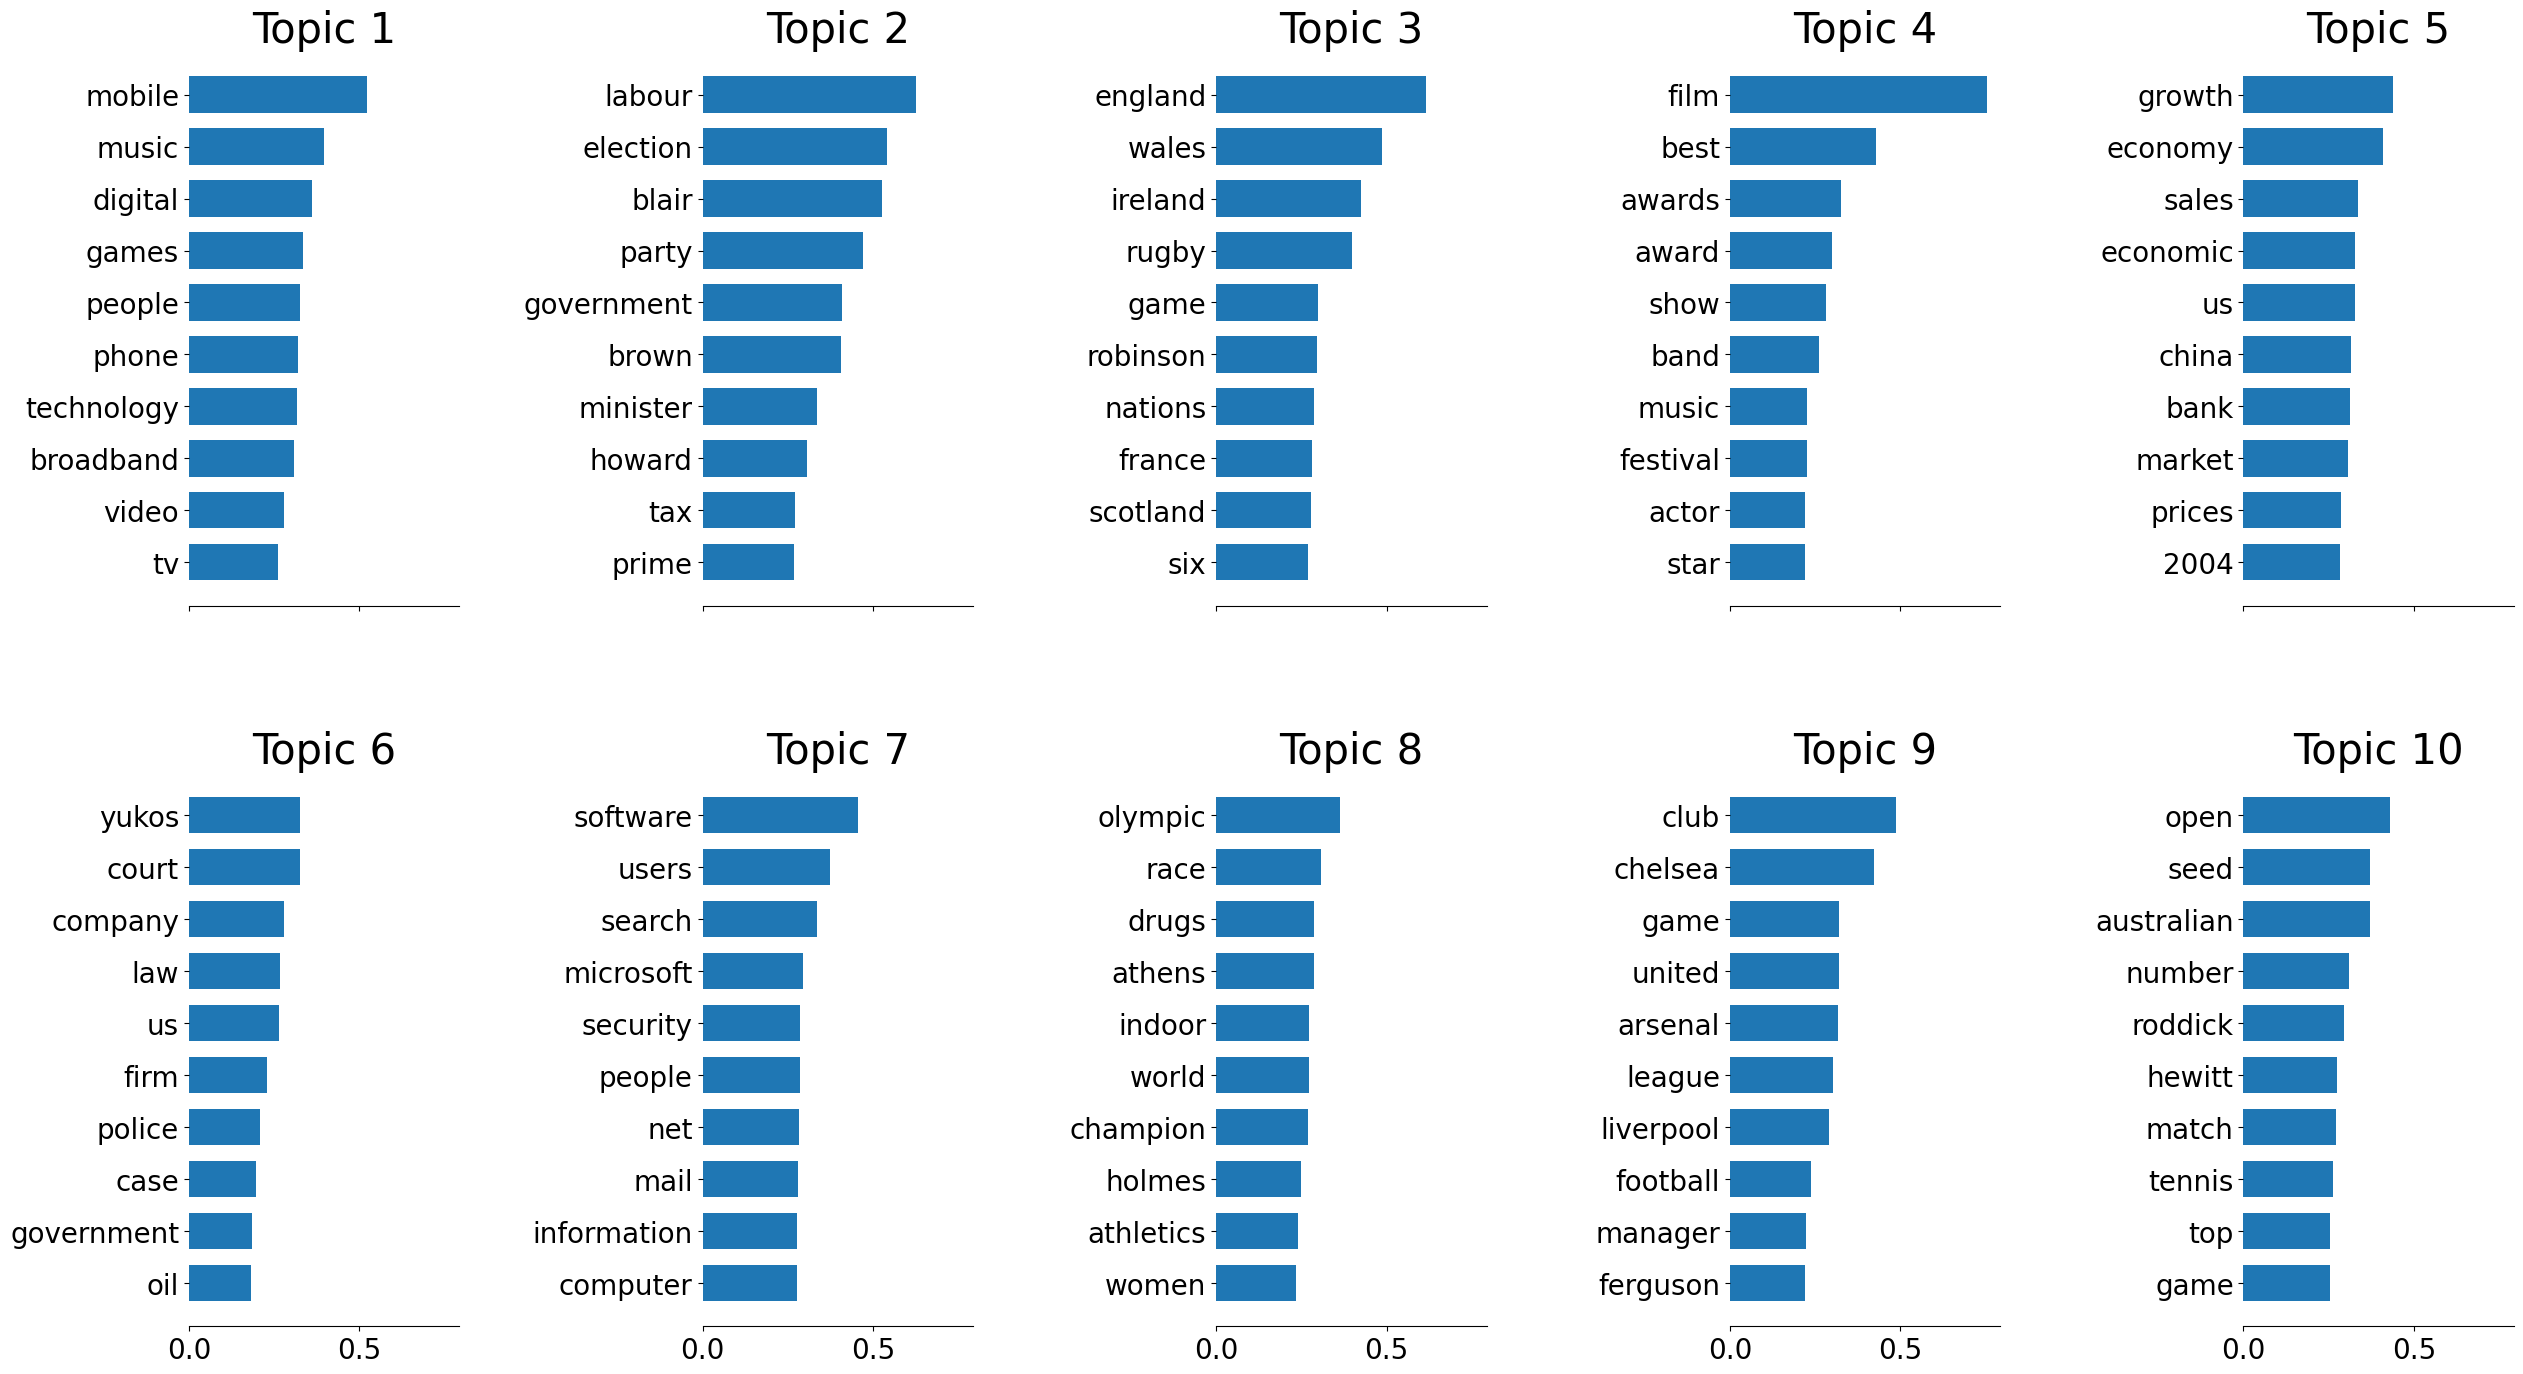

In [13]:
plot_top_words(nmf, vectorizer.get_feature_names_out(), 10)

In [14]:
Z = nmf.transform(X)   # Returns [Documents x Topics] matrix

In [15]:
Z.shape

(2225, 10)

In [16]:
nmf.components_  # Returns [Topics x Words] matrix

array([[0.00108006, 0.08852999, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.00153897, 0.10125217, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.00783279, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.00620508, 0.00957756, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.01468373, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.04713621, 0.        , ..., 0.        , 0.01761751,
        0.        ]])

In [18]:
nmf.components_.shape

(10, 29270)

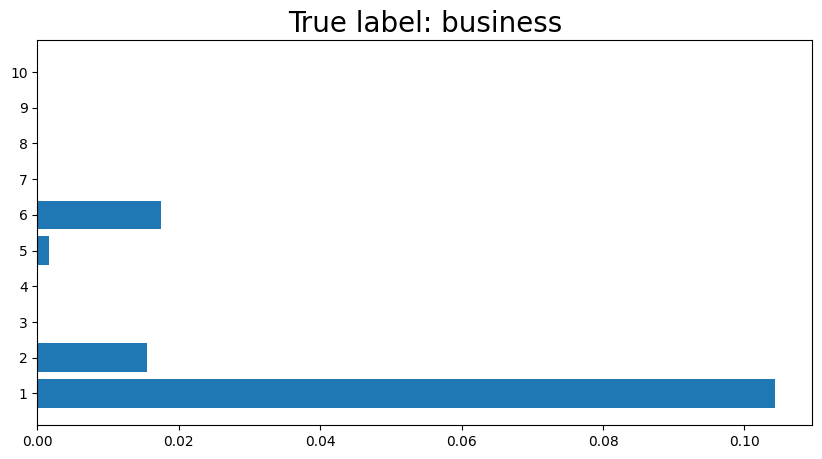

In [19]:
i = np.random.choice(len(df))
z = Z[i]
topics = np.arange(10) + 1

fig,ax = plt.subplots(figsize=(10,5))
ax.barh(topics, z)
ax.set_yticks(topics)
ax.set_title(f'True label: {df["labels"][i]}', fontsize=20)
plt.show()

In [20]:
def wrap(x):

    return textwrap.fill(x, replace_whitespace=False, fix_sentence_endings=True)

In [21]:
print(wrap(df.iloc[i]['text']))

BT offers equal access to rivals

BT has moved to pre-empt a possible
break-up of its business by offering to cut wholesale broadband prices
and open its network to rivals.

The move comes after telecom
regulator Ofcom said in November that the firm must offer competitors
"real equality of access to its phone lines". At the time, Ofcom
offered BT the choice of change or splitting into two.  Ofcom is
carrying out a strategic review aimed at promoting greater competition
in the UK telecom sector.  BT's competitors have frequently accused it
of misusing its status as the former telecoms monopoly and controller
of access to many customers to favour its own retail arm.

This latest
submission was delivered to the watchdog ahead of a deadline for the
second phase of its review.

"Central to the proposals are plans by BT
to offer operators lower wholesale prices, faster broadband services
and transparent, highly-regulated access to BT's local network," the
former monopoly said in a statement.